# WAKIS — Pillbox cavity: PEC eigenmodes and conductive-wall SIBC validation

**Aim:** Compute lossless pillbox modes, estimate wall-loss $Q$ from the conformal SIBC perturbation, and independently confirm it by a **direct FD frequency sweep**. The conductive shell is loaded from the existing `007_lossymetal_shell.stl`; `007_vacuum_cavity.stl` is used to inspect the vacuum geometry. Compare the calculated resonance frequencies and $Q$ factors against **CST** values for exactly the same geometry and boundary conditions.

**Model requirements:** current conformal material fix, Fortran (`order="F"`) FD indexing, and SIBC boundary implementation. `conformal_pec_snap_fraction=0.2` is used for both PEC and SIBC. **The current eigenmode solver supports lossless PEC only**; $Q$ is computed via perturbation or driven FD resonance fitting.

**Geometry caveat:** The pipe mouths / outer truncation are closed with **PEC**. Reproduce these terminating planes in CST. This notebook has not been run with your local STL files.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
from scipy.constants import pi
from scipy.sparse import diags
from scipy.optimize import least_squares
from wakis import GridFIT3D, WakeSolver
from wakis.solverFIT3D_FD import SolverFIT3D_FD


BETA = 1.0
Q = 1.0e-9
SIGMAZ = 0.1
WAKELENGTH = 100.0

XSOURCE = 0.0
YSOURCE = 0.0
XTEST = 0.0
YTEST = 0.0

# Keep the integration interval identical between TD and the current FD
# implementation. If boundary contamination becomes relevant later, introduce
# the same integration mask explicitly in both methods.
SKIP_CELLS = 0

## 1. Locate the STL files and inspect bounds

Run this notebook from `notebooks/` or another WAKIS repository directory. If your files are elsewhere, update `stl_dir` manually. The vacuum mesh is used for bounds and visualization; the **lossy-metal shell** is the only STL assigned to the solver.

In [2]:
root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
search_dirs = [p / "tests" / "stl" for p in root_candidates]
search_dirs += [p / "notebooks" / "stl" for p in root_candidates]
search_dirs += [p / "stl" for p in root_candidates]

shell_path = next(
    (
        p / "007_lossymetal_shell.stl"
        for p in search_dirs
        if (p / "007_lossymetal_shell.stl").is_file()
    ),
    None,
)
assert shell_path is not None, (
    "Cannot find 007_lossymetal_shell.stl. Set shell_path manually to its absolute path."
)
vacuum_path = shell_path.with_name("007_vacuum_cavity.stl")
assert vacuum_path.is_file(), f"Vacuum reference STL missing: {vacuum_path}"

shell_mesh = pv.read(str(shell_path))
vacuum_mesh = pv.read(str(vacuum_path))
print("Shell STL:", shell_path)
print("Vacuum bounds:", vacuum_mesh.bounds)
print("Shell bounds :", shell_mesh.bounds)
print("Volume (vacuum, shell):", vacuum_mesh.volume, shell_mesh.volume)

Shell STL: /home/hschreib/Documents/Wakis/WAKIS/tests/stl/007_lossymetal_shell.stl
Vacuum bounds: BoundsTuple(x_min = -0.23000000417232513,
            x_max =  0.23000000417232513,
            y_min = -0.23000000417232513,
            y_max =  0.23000000417232513,
            z_min = -0.25,
            z_max =  0.550000011920929)
Shell bounds : BoundsTuple(x_min = -0.25999999046325684,
            x_max =  0.25999999046325684,
            y_min = -0.25999999046325684,
            y_max =  0.25999999046325684,
            z_min = -0.25,
            z_max =  0.550000011920929)
Volume (vacuum, shell): 0.051777601439378394 0.026403651106294345


In [3]:
p = pv.Plotter(notebook=True)
p.add_mesh(shell_mesh, color="silver", opacity=0.18)
p.add_mesh(vacuum_mesh, color="steelblue", opacity=0.4)
p.show_axes()
p.show()

Widget(value='<iframe src="http://localhost:38963/index.html?ui=P_0x7fcaa437a7b0_0&reconnect=auto" class="pyvi…

## 2. Grid and material settings

Select computational box based on the **vacuum** mesh bounds, including a modest margin. Check the plotted geometry: the truncation planes must not create isolated vacuum islands or unwanted narrow gaps. For a closed shell, these bounds may extend into metal and cause SIBC/PEC intersections at the outer PEC boundary.

Start with a small grid. Increase the resolution only after the first successful eigenmode and SIBC checks. All dimensions are assumed in **meters**; check STL units before proceeding.

In [4]:
sigma_wall = 1e3  # S/m; replace with CST wall conductivity
mu_r_wall = 1.0
eta = 0.2
Nx, Ny, Nz = 18, 18, 26  # coarse initial run; refine after initial success

vb = np.array(vacuum_mesh.bounds).reshape(3, 2)
size = vb[:, 1] - vb[:, 0]
print("Vacuum size [m]:", size)
assert np.all(size > 0)
assert 1e-4 < size.max() < 10, (
    "Unexpected STL units: verify that coordinates are meters."
)

# A little space around the cavity/beam-pipe volume; PEC truncation outside.
padding = 0.03 * size
xmin, ymin, zmin = vb[:, 0] - padding
xmax, ymax, zmax = vb[:, 1] + padding
print("Simulation domain:", (xmin, xmax, ymin, ymax, zmin, zmax))

Vacuum size [m]: [0.46000001 0.46000001 0.80000001]
Simulation domain: (np.float64(-0.24380000442266464), np.float64(0.24380000442266464), np.float64(-0.24380000442266464), np.float64(0.24380000442266464), np.float64(-0.2740000003576279), np.float64(0.5740000122785568))


## 3. Build PEC and SIBC models

Both solvers use **identical STL geometry and snapping**. For the SIBC solid the bulk is excluded from E DOFs, but the original wall conductivity must remain available for the surface-impedance correction.

If the low-side SIBC-face exception occurs, inspect which faces intersect the outer PEC termination. The current implementation cannot apply SIBC directly to unrepresented magnetic boundary DOFs; do **not** silently ignore a physically exposed wall.

In [11]:
def make_solver(kind):
    mat = [np.inf, 1.0, 0.0] if kind == "pec" else [1.0, mu_r_wall, sigma_wall]
    grid = GridFIT3D(
        xmin=xmin,
        xmax=xmax,
        ymin=ymin,
        ymax=ymax,
        zmin=zmin,
        zmax=zmax,
        Nx=Nx,
        Ny=Ny,
        Nz=Nz,
        stl_solids={"shell": str(shell_path)},
        stl_materials={"shell": mat},
        stl_material_types={"shell": kind},
        geometry_mode="conformal",
        stl_method="interior_points",
        bg_material_type="normal",
        conformal_pec_snap_fraction=eta,
        verbose=0,
    )
    return SolverFIT3D_FD(
        grid=grid,
        use_stl=True,
        use_sibc=True,
        bc_low=["PEC"] * 3,
        bc_high=["PEC"] * 3,
        verbose=0,
    )


pec = make_solver("pec")
sibc = make_solver("sibc")
print("PEC/SIBC active E DOFs:", len(pec.free_E_idx), len(sibc.free_E_idx))
assert np.array_equal(pec.free_E_idx, sibc.free_E_idx), "PEC/SIBC E DOFs differ"
assert np.allclose(pec.Meps.diagonal(), sibc.Meps.diagonal()), "Meps differs"
assert np.allclose(pec.Mnu.diagonal(), sibc.Mnu.diagonal()), "Mnu differs"
assert sibc.has_sibc, "No SIBC coefficients detected"
active_faces = sibc.sibc_g > 0
rows_active = np.diff(sibc.C_red.tocsr().indptr) > 0
print(
    "SIBC faces / coupled faces:",
    active_faces.sum(),
    (active_faces & rows_active).sum(),
)
print("Uncoupled SIBC faces:", (active_faces & ~rows_active).sum())

Generating grid with 8424 mesh cells...


/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4428: UserWarning: Conformal geometry diagnostics:
1096 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
48 edges contain multiple crossing positions. 0 of these are currently used by the conformal discretization; one representative crossing is selected on each edge.
48 edges cross the same STL at more than one distinct position. The geometry on these edges is not fully resolved by the current single-crossing treatment.
  dual z-edge (3, 7, 7): shell
  dual z-edge (3, 7, 17): shell
  dual z-edge (3, 8, 7): shell
  dual z-edge (3, 8, 17): shell
  dual z-edge (3, 9, 7): shell
  ... and 43 more.
  self._warn_interface_diagnostics()


Initializing Electromagnetic solver...
Generating grid with 8424 mesh cells...
Initializing Electromagnetic solver...


NotImplementedError: SIBC for conductive STL materials is currently not supported with geometry_mode='conformal'.

## 4. PEC eigenmodes

Use a shift-invert search near the expected pillbox TM-like resonance. The fundamental of a **closed, ideal cylindrical cavity** gives the rough scale $f_{010}\approx c\,2.4048/(2\pi R)$, but the beam-pipe transitions in the STL shift frequencies. The approximate effective radius derived from STL bounds is **only a search hint**, not an analytical validation result. Identify the desired mode from its field pattern and (if known) its CST frequency.

In [6]:
from scipy.constants import c

# Use the transverse vacuum bounding-box span as a rough diameter.
R_guess = 0.25 * (size[0] + size[1])
f_guess = c * 2.4048255577 / (2 * pi * R_guess)
print(f"Rough TM010 search target: {f_guess / 1e9:.4f} GHz")

# Override this with the CST eigenfrequency if available.
target_frequency = f_guess
n_modes = 8
f_modes, modes, lambdas = pec.solve_eigenmodes(
    n_modes=n_modes, target_frequency=target_frequency
)
for k, f in enumerate(f_modes):
    print(f"mode {k}: {f / 1e9:.9f} GHz")

Rough TM010 search target: 0.4989 GHz
mode 0: 0.549153303 GHz
mode 1: 0.549612516 GHz
mode 2: 0.550931029 GHz
mode 3: 0.551894903 GHz
mode 4: 0.553594605 GHz
mode 5: 0.601916043 GHz
mode 6: 0.602975806 GHz
mode 7: 0.603930276 GHz


## 5. Choose the mode

Inspect the modes before deciding which one to compare to CST. The default below picks the nearest frequency to `target_frequency`; **it does not prove TM010 mode identity**. Change `mode_index` to the desired mode after inspecting its field pattern.

Selected mode 0: 0.549153303 GHz


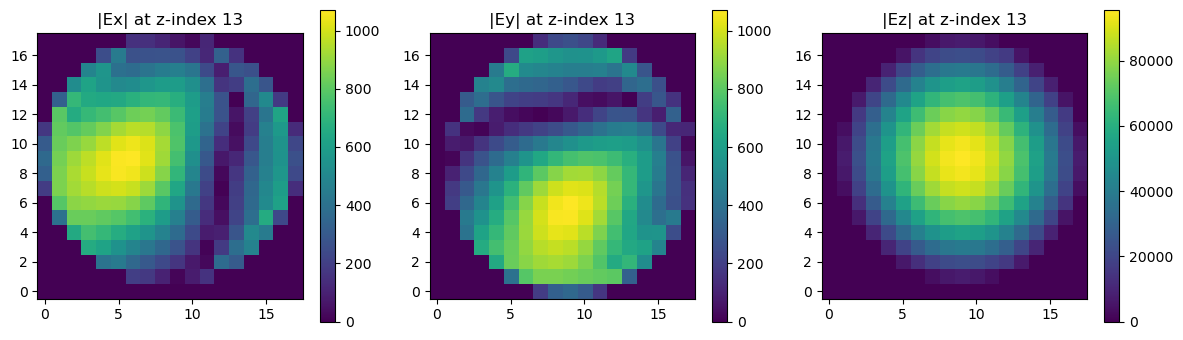

In [7]:
mode_index = int(np.argmin(abs(f_modes - target_frequency)))  # inspect / override!
f0 = float(f_modes[mode_index])
omega0 = 2 * pi * f0
e = np.asarray(modes[:, mode_index], dtype=complex)
print(f"Selected mode {mode_index}: {f0 / 1e9:.9f} GHz")

# Reconstruct component-wise E-grid voltages; reshape in FIT Fortran order.
E = np.zeros(3 * pec.N, dtype=complex)
E[pec.free_E_idx] = e
Ex, Ey, Ez = [
    E[j * pec.N : (j + 1) * pec.N].reshape((pec.Nx, pec.Ny, pec.Nz), order="F")
    for j in range(3)
]

# Midplane slice: qualitative mode-ID; sample index is a FIT mesh index.
iz = pec.Nz // 2
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, data, label in zip(axs, (Ex, Ey, Ez), ("Ex", "Ey", "Ez")):
    im = ax.imshow(np.abs(data[:, :, iz]).T, origin="lower", aspect="equal")
    ax.set_title(f"|{label}| at z-index {iz}")
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 6. First-order wall-loss estimate

Calculate the difference in magnetic stiffness between the PEC and SIBC solvers at the PEC eigenfrequency, then project onto the selected PEC eigenvector:

\[
\delta\omega \approx \frac{\mathbf e^H(\mathbf K_{\rm SIBC}-\mathbf K_{\rm PEC})\mathbf e}
{2\omega_0\mathbf e^H\mathbf M_\varepsilon\mathbf e},\qquad
Q_{\rm 1st}=\frac{\omega_0}{2\operatorname{Im}\delta\omega}.
\]

For $e^{+j\omega t}$, positive $\operatorname{Im}\delta\omega$ means damping.

In [8]:
C = sibc.C_red.tocsr()
mnu = sibc.Mnu.diagonal()
D = sibc._build_sibc_diagonal(omega0)
K_sibc = (C.T @ diags(mnu / D) @ C).tocsr()
dK = K_sibc - pec.SL
denom = 2 * omega0 * np.vdot(e, pec.Meps @ e)
domega = np.vdot(e, dK @ e) / denom
assert domega.imag > 0, "Nonpositive damping: inspect SIBC geometry/operator"
Q_first = omega0 / (2 * domega.imag)
f_pred = f0 + domega.real / (2 * pi)
gamma_pred = domega.imag / (2 * pi)
print(f"PEC frequency             : {f0 / 1e9:.9f} GHz")
print(f"SIBC complex shift        : {domega / (2 * pi):+.5f} Hz")
print(f"Predicted resonance       : {f_pred / 1e9:.9f} GHz")
print(f"Q first order             : {Q_first:.3f}")
print(f"Predicted FWHM            : {2 * gamma_pred:.3f} Hz")

PEC frequency             : 0.549153303 GHz
SIBC complex shift        : -1159907.78836+1077573.04112j Hz
Predicted resonance       : 0.547993395 GHz
Q first order             : 254.810
Predicted FWHM            : 2155146.082 Hz


## 7. Direct FD resonance sweep

This is a modal **driven-response** validation of the frequency-dependent SIBC operator, not yet a beam impedance. Excite with the selected PEC eigenvector and fit the resulting complex response. For coarse meshes the initial SIBC frequency shift can be appreciable; use the predicted linewidth as the local frequency scale.

In [ ]:
source = np.zeros(3 * sibc.N, dtype=complex)
source[sibc.free_E_idx] = pec.Meps @ e

n_samples = 25  # increase to 41 for final comparison
f_sweep = np.linspace(f_pred - 6 * gamma_pred, f_pred + 6 * gamma_pred, n_samples)
H = np.empty(n_samples, dtype=complex)
for k, f in enumerate(f_sweep):
    E_full = sibc.solve(omega=2 * pi * f, source=source)
    E_red = E_full[sibc.free_E_idx]
    H[k] = np.vdot(e, pec.Meps @ E_red) / np.vdot(e, pec.Meps @ e)

x = (f_sweep - f_pred) / gamma_pred
scale = np.max(np.abs(H))
y = H / scale


def model(p):
    xr, log_g, Br, Bi, Cr, Ci = p
    return (Cr + 1j * Ci) + (Br + 1j * Bi) / (x - xr - 1j * np.exp(log_g))


def residual(p):
    r = model(p) - y
    return np.r_[r.real, r.imag]


B0 = (y[np.argmin(abs(x))] - (y[0] + y[-1]) / 2) * (-1j)
C0 = (y[0] + y[-1]) / 2
fit = least_squares(residual, [0, 0, B0.real, B0.imag, C0.real, C0.imag], max_nfev=3000)
assert fit.success, fit.message
xr, log_g = fit.x[:2]
f_direct = f_pred + xr * gamma_pred
gamma_direct = np.exp(log_g) * gamma_pred
Q_direct = f_direct / (2 * gamma_direct)
H_fit = scale * model(fit.x)

print(f"f_PEC                 = {f0 / 1e9:.9f} GHz")
print(f"f_direct FD           = {f_direct / 1e9:.9f} GHz")
print(f"Q_first              = {Q_first:.4f}")
print(f"Q_direct             = {Q_direct:.4f}")
print(f"Q_direct / Q_first   = {Q_direct / Q_first:.6f}")
print(f"Complex fit residual = {np.linalg.norm(H - H_fit) / np.linalg.norm(H):.3e}")

plt.figure(figsize=(7.5, 4.2))
plt.plot((f_sweep - f_pred) / 1e3, abs(H), "o", label="Direct FD")
plt.plot((f_sweep - f_pred) / 1e3, abs(H_fit), "-", label="Complex pole fit")
plt.xlabel("Frequency relative to predicted resonance [kHz]")
plt.ylabel("Magnitude of modal response [a.u.]")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

KeyboardInterrupt: 

: 

## 8. CST comparison (enter reference results)

Use **the same STL geometry, conductivity, boundary planes, and selected mode** in CST. For a CST surface-impedance treatment, verify that the compared $Q$ represents conductor losses (not radiation or external coupling). If CST uses volumetric lossy metal, confirm the mesh resolves skin depth or uses an appropriate surface-loss model.

In [ ]:
# Replace None with CST results for the SAME mode/configuration:
f_cst_hz = None
Q_cst = None

if f_cst_hz is not None:
    print(f"PEC vs CST frequency error: {100 * (f0 / f_cst_hz - 1):+.3f}%")
if Q_cst is not None:
    print(f"Q_first / Q_CST : {Q_first / Q_cst:.6f}")
    print(f"Q_direct / Q_CST: {Q_direct / Q_cst:.6f}")

CST resonance frequency : 547.238063 MHz
CST FWHM                : 0.4096 MHz
CST Q                   : 1336.14
FIT Q (first-order)     : 254.81
Q_FIT / Q_CST           : 0.1907
Relative fit residual   : 9.039e-01
Points per FWHM         : 0.40


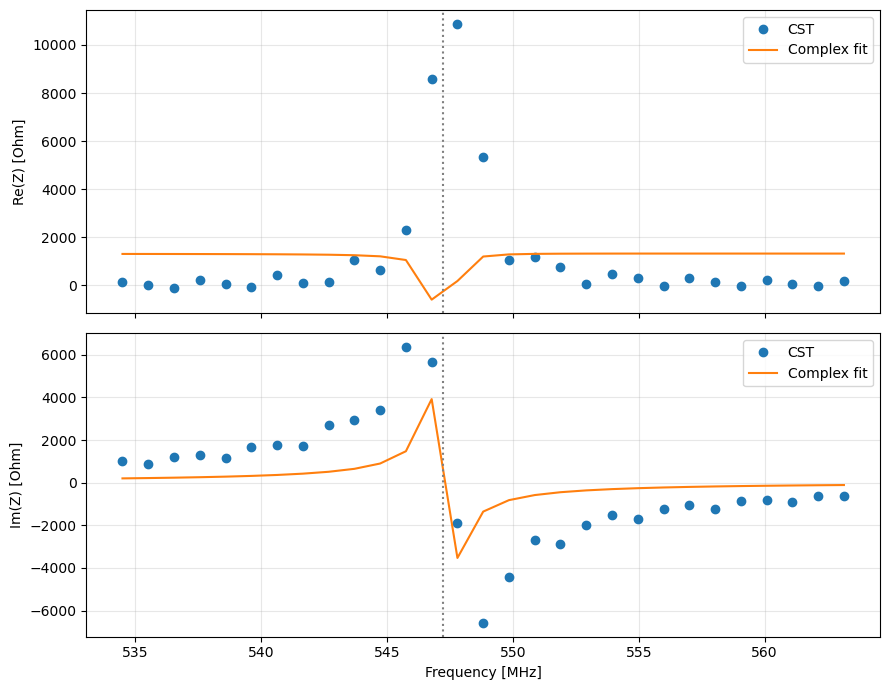

Q_CST             = 1336.14
Q_FIT first-order = 254.81
Q_first / Q_CST   = 0.190706


In [9]:
from pathlib import Path
from scipy.optimize import least_squares
import numpy as np
import matplotlib.pyplot as plt

# --- Read CST longitudinal impedance ---
filename = Path("cavity_long_imp_sigma_sibc_1e3.txt")  # Adjust filename

data = np.loadtxt(filename, comments="#")
f_cst = data[:, 0]
Z_cst = data[:, 1] + 1j * data[:, 2]


from scipy.optimize import least_squares

# Select the resonance near the PEC eigenfrequency
f_target = f0
fit_window = 15e6

mask = np.abs(f_cst - f_target) <= fit_window
f = f_cst[mask]
Z = Z_cst[mask]

df = np.median(np.diff(f))
i_peak = np.argmax(Z.real)
f_peak = f[i_peak]

# Work in MHz to improve numerical conditioning
x = (f - f_peak) / 1e6
y = Z / np.max(np.abs(Z))


def fit_linear(fr, gamma):
    # Complex pole plus constant background
    pole = 1 / (x - fr + 1j * gamma)
    M = np.column_stack([pole, np.ones_like(pole)])
    coeff, *_ = np.linalg.lstsq(M, y, rcond=None)
    return M @ coeff, coeff


def residual(p):
    y_fit, _ = fit_linear(*p)
    diff = y_fit - y
    return np.r_[diff.real, diff.imag]


# Initial width from FIT Q (used only as a starting guess)
gamma_guess = f_peak / (2 * Q_first) / 1e6

lower = [-3 * df / 1e6, 0.2 * df / 1e6]
upper = [3 * df / 1e6, fit_window / 1e6]

# Multiple starting points
best = None

for fr0 in np.linspace(lower[0], upper[0], 7):
    for gamma0 in np.geomspace(lower[1], upper[1], 8):
        result = least_squares(
            residual, [fr0, gamma0], bounds=(lower, upper), max_nfev=2000
        )
        if best is None or result.cost < best.cost:
            best = result

fr_cst = f_peak + best.x[0] * 1e6
gamma_cst = best.x[1] * 1e6
Q_cst = fr_cst / (2 * gamma_cst)

y_fit, coeff = fit_linear(*best.x)
Z_fit = y_fit * np.max(np.abs(Z))
fit_error = np.linalg.norm(Z_fit - Z) / np.linalg.norm(Z)

print(f"CST resonance frequency : {fr_cst / 1e6:.6f} MHz")
print(f"CST FWHM                : {2 * gamma_cst / 1e6:.4f} MHz")
print(f"CST Q                   : {Q_cst:.2f}")
print(f"FIT Q (first-order)     : {Q_first:.2f}")
print(f"Q_FIT / Q_CST           : {Q_first / Q_cst:.4f}")
print(f"Relative fit residual   : {fit_error:.3e}")
print(f"Points per FWHM         : {2 * gamma_cst / df:.2f}")

# Plot fit
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

for ax, measured, fitted, label in [
    (axes[0], Z.real, Z_fit.real, "Re(Z) [Ohm]"),
    (axes[1], Z.imag, Z_fit.imag, "Im(Z) [Ohm]"),
]:
    ax.plot(f / 1e6, measured, "o", label="CST")
    ax.plot(f / 1e6, fitted, "-", label="Complex fit")
    ax.axvline(fr_cst / 1e6, color="gray", ls=":")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    ax.legend()

axes[1].set_xlabel("Frequency [MHz]")
plt.tight_layout()
plt.show()


# --- Compare against WAKIS ---
print(f"Q_CST             = {Q_cst:.2f}")
print(f"Q_FIT first-order = {Q_first:.2f}")
print(f"Q_first / Q_CST   = {Q_first / Q_cst:.6f}")

if "Q_direct" in globals():
    print(f"Q_FIT direct      = {Q_direct:.2f}")
    print(f"Q_direct / Q_CST  = {Q_direct / Q_cst:.6f}")

In [10]:
FMIN = 1.0e7
FMAX = 1.0e9
N_FREQ = 100

f_fd = np.linspace(
    FMIN,
    FMAX,
    N_FREQ,
)


wake_fd = WakeSolver(
    q=Q,
    sigmaz=SIGMAZ,
    beta=BETA,
    xsource=XSOURCE,
    ysource=YSOURCE,
    xtest=XTEST,
    ytest=YTEST,
    fmax=FMAX,
    skip_cells=SKIP_CELLS,
    save=False,
    verbose=1,
)

e_modes = np.asarray(modes)
# 1. Constant modal admittance: Y_n(omega_n)
Z_const, _, modal = pec.eigenmode_longitudinal_impedance(
    frequencies=f_fd,
    eigenfrequencies=f_modes,
    eigenvectors=e_modes,
    wake=wake_fd,
    include_sibc=True,
    sibc_mode="resonance",
    return_modal_parameters=True,
)

# 2. Frequency-dependent modal admittance: Y_n(omega)
Z_freq, _ = pec.eigenmode_longitudinal_impedance(
    frequencies=f_fd,
    eigenfrequencies=f_modes,
    eigenvectors=e_modes,
    wake=wake_fd,
    include_sibc=True,
    sibc_mode="frequency",
)

# Compare against CST
plt.figure(figsize=(9, 5))
plt.plot(f_cst / 1e6, Z_cst.real, label="CST")
plt.plot(f_eval / 1e6, Z_const.real, label="WAKIS: Constant Yn")
plt.plot(f_eval / 1e6, Z_freq.real, "--", label="WAKIS: Yn(f)")
plt.xlabel("Frequency [MHz]")
plt.ylabel("Re(Z_long) [Ohm]")
plt.xlim(520, 580)
plt.grid(True)
plt.legend()
plt.show()

Initializing Wakefield parameters...
Total solver initialization time: 6.461143493652344e-05 s


ValueError: include_sibc=True requires a solver with SIBC geometry (self.has_sibc is False).

## Interpretation and limitations

- Check mode identity **by field pattern**, not only the nearest eigenfrequency.
- The numerical result can be affected by the shell geometry near beam-pipe openings, outer PEC terminations, conformal snapping, and inactive SIBC faces.
- This first sweep validates the same mode with **two independent solution procedures**, but the first-order estimate and direct FD solve share the same SIBC operator. CST is an external validation of wall-loss magnitude.
- Increase the mesh resolution and repeat the comparison after the first successful coarse run. A mesh convergence study is needed for quantitative claims.
- If no SIBC surfaces are detected, inspect STL orientation/volume, region assignments, and surface-coupling diagnostics before proceeding.
